# 사출성형 공정데이터 기반 품질불량 사전예측 — 재현 가능한 Baseline

**2026 제6회 K-인공지능 제조데이터 분석 경진대회 · 사출성형기 AI 데이터셋**

이 노트북은 *분석 · 시각화 · 설명* 을 위한 문서입니다. 실제 계산 코드는 모두 `baseline.py` 에 함수 단위로 들어 있고,
노트북은 그 함수를 순서대로 호출하면서 **결과를 읽는 방법**을 설명합니다.
(같은 내용을 처음부터 끝까지 자동으로 실행하려면 터미널에서 `python baseline.py` 를 실행하면 됩니다.)

### 이번 단계의 목표
1. 공정 종료 후 최종 검사 이전에 **정상/불량을 예측**하는 모델의 *신뢰할 수 있는 출발점(baseline)* 을 만든다.
2. 최소 2개 이상의 모델을 **같은 조건에서 공정하게 비교**한다 (Dummy / Logistic Regression / Random Forest / HistGradientBoosting).
3. F1-score 외에 Precision · Recall · ROC-AUC · PR-AUC · Confusion Matrix(TN/FP/FN/TP) 를 함께 본다.
4. FN(놓친 불량) / FP(오탐) 가 어떤 조건에서 생기는지 **후속 분석할 수 있는 파일**을 남긴다.
5. 검사 우선순위 확장을 위해 **불량 확률(predict_proba)** 을 저장한다.

### 이번 단계에서 하지 않는 것
최고 성능 경쟁(복잡한 feature engineering, ensemble, Optuna 튜닝, SMOTE)은 하지 않습니다.
대신 **데이터 누수(leakage)** 와 **잘못된 가정** 을 피하는 데 집중합니다.

> 용어 메모 (팀원용)
> * **데이터 누수**: 시험 문제(validation)의 답을 미리 공부(train)에 섞어 넣는 것. 성능이 실제보다 좋아 보이게 만든다.
> * **Precision(정밀도)**: "불량이라고 예측한 것 중 진짜 불량 비율". **Recall(재현율)**: "진짜 불량 중 잡아낸 비율".
> * **F1**: Precision 과 Recall 의 조화평균. **PR-AUC**: threshold 를 바꿔가며 본 Precision-Recall 곡선의 면적(불량 순위를 얼마나 잘 매기는지).
> * **FN(False Negative)**: 불량인데 정상이라고 놓친 것 — 제조 현장에서 가장 비싼 실수. **FP**: 정상인데 불량이라고 한 것 — 불필요한 검사.

In [1]:
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

import baseline as bl   # 모든 함수는 baseline.py 에 있다

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("default")   # 경고를 무작정 숨기지 않는다

bl.make_dirs()
print("데이터 폴더:", bl.DATA_DIR)
print("결과 폴더  :", bl.OUTPUT_DIR)
print("random seed:", bl.RANDOM_STATE, "| 불량으로 가정한 클래스 값:", bl.POSITIVE_CLASS)

데이터 폴더: /home/claude/project/data
결과 폴더  : /home/claude/project/outputs
random seed: 42 | 불량으로 가정한 클래스 값: 1


## 1. 데이터 로딩 및 기본 진단

먼저 4개 CSV 를 읽고, **가정 없이** 구조를 확인합니다.
- labeled 2개 (CN7, RG3): 정답(`PassOrFail`) 이 있는 데이터 → 학습/평가용
- unlabeled 2개: 정답이 없는 데이터 → 최종 모델로 예측할 대상

In [2]:
dfs = bl.load_data()
bl.check_column_consistency(dfs)

[load] labeled_cn7    (1211, 26)     <- moldset_labeled_cn7.csv
[load] labeled_rg3    (1182, 26)     <- moldset_labeled_rg3.csv


[load] unlabeled_cn7  (35239, 25)    <- moldset_unlabeled_cn7.csv


[load] unlabeled_rg3  (35941, 25)    <- moldset_unlabeled_rg3.csv

------------------------------------------------------------------------------
[1] labeled / unlabeled 컬럼 일치 여부
------------------------------------------------------------------------------
CN7: labeled(타깃 제외) == unlabeled ? True | labeled 에만: [] | unlabeled 에만: []
RG3: labeled(타깃 제외) == unlabeled ? True | labeled 에만: [] | unlabeled 에만: []
CN7 vs RG3 labeled 컬럼 순서/이름 동일 ? True


In [3]:
# shape / dtype / 결측 / 중복 / 클래스 비율 / 기술통계 / unique 수 / 상수 컬럼
inspections = pd.concat([bl.inspect_dataset(k, df) for k, df in dfs.items()], ignore_index=True)
inspections.to_csv(bl.EDA_DIR / "inspection_summary.csv", index=False)


------------------------------------------------------------------------------
[1] 기본 진단 — labeled_cn7
------------------------------------------------------------------------------
shape: (1211, 26)
columns: ['Unnamed: 0', 'PassOrFail', 'Injection_Time', 'Filling_Time', 'Plasticizing_Time', 'Cycle_Time', 'Clamp_Close_Time', 'Cushion_Position', 'Plasticizing_Position', 'Clamp_Open_Position', 'Max_Injection_Speed', 'Max_Screw_RPM', 'Average_Screw_RPM', 'Max_Injection_Pressure', 'Max_Switch_Over_Pressure', 'Max_Back_Pressure', 'Average_Back_Pressure', 'Barrel_Temperature_1', 'Barrel_Temperature_2', 'Barrel_Temperature_3', 'Barrel_Temperature_4', 'Barrel_Temperature_5', 'Barrel_Temperature_6', 'Hopper_Temperature', 'Mold_Temperature_3', 'Mold_Temperature_4']
결측치 총합: 0
중복 행 수 (모든 컬럼 기준): 0
중복 행 수 (ID 제외, 공정변수 기준): 605  (50.0%)
PassOrFail class count: {0: 1194, 1: 17}
PassOrFail class ratio: {0: 0.986, 1: 0.014}
상수 컬럼: ['Clamp_Open_Position']
거의 상수 컬럼(최빈값 비율 >= 99%): 없음
                  c

결측치 총합: 0
중복 행 수 (모든 컬럼 기준): 0
중복 행 수 (ID 제외, 공정변수 기준): 6234  (17.3%)
상수 컬럼: 없음
거의 상수 컬럼(최빈값 비율 >= 99%): 없음
                  column   dtype  n_unique  top_value_share       mean        std        min        max
              Unnamed: 0   int64     35941            0.000 423752.208 225573.788 119515.000 795309.000
          Injection_Time float64        91            0.285      0.000      1.000     -1.151      2.801
            Filling_Time float64        97            0.285      0.000      1.000     -1.308      1.663
       Plasticizing_Time float64       470            0.203      0.000      1.000     -1.534      4.639
              Cycle_Time float64       371            0.136      0.000      1.000     -4.268      1.745
        Clamp_Close_Time float64        88            0.131     -0.000      1.000     -1.634      5.977
        Cushion_Position float64        68            0.136     -0.000      1.000     -1.376      0.762
   Plasticizing_Position float64       207            0.225 

### 1-1. 공정변수 값이 이미 스케일링된 데이터인가?

값이 -1 ~ 2 근처의 소수로 보여서 "이미 표준화된 것 같다"는 인상을 받지만, **실제 평균/표준편차를 파일별로 계산해서** 확인합니다.

In [4]:
scaling = bl.check_scaling(dfs)


------------------------------------------------------------------------------
[1] 공정변수 스케일 확인 (파일별 평균/표준편차)
------------------------------------------------------------------------------
      dataset  n_features  max_abs_mean  n_std_close_to_1  n_std_zero    std_zero_columns
  labeled_cn7          24  4.630532e-12                23           1 Clamp_Open_Position
  labeled_rg3          24  2.788886e-12                23           1 Clamp_Open_Position
unlabeled_cn7          24  9.859161e-15                24           0                    
unlabeled_rg3          24  7.047502e-15                24           0                    
-> 모든 파일에서 평균≈0, 표준편차≈1 이면 '파일별로 각각 표준화된 데이터' 이다.
   (이 경우 CN7/RG3, labeled/unlabeled 사이의 절대적인 크기 비교는 불가능하고,
    분포의 '모양' 차이만 비교할 수 있다. 원본 단위 데이터는 제공되지 않았다.)


**확인 결과** — 4개 파일 모두, 모든 공정변수의 평균이 0, 표준편차가 1 입니다. 즉 **파일마다 따로(독립적으로) z-score 표준화된 데이터**입니다.
이것은 아래 두 가지 중요한 제약을 만듭니다.

1. **CN7 과 RG3 의 "평균 차이"는 계산해도 0 이 나온다.** 표준화가 평균을 0 으로 맞춰 놓았기 때문에, 두 제품의 온도·압력이 실제로 얼마나 다른지는 이 데이터로는 알 수 없고 분포의 *모양* 차이만 볼 수 있습니다.
2. **labeled 와 unlabeled 도 따로 표준화되었다.** 같은 z-score 값(예: 0.5)이 두 파일에서 같은 물리량을 뜻한다는 보장이 없습니다. → unlabeled 예측 결과는 확률의 절대값보다 **순위(ranking)** 로 해석해야 하고, 원본 단위 데이터(또는 스케일링에 쓰인 평균/표준편차)를 확보하는 것이 다음 단계의 TODO 입니다.

또한 `Clamp_Open_Position` 은 labeled 두 파일에서 **값이 하나뿐(상수, 표준편차 0)** 이므로 학습에 아무 정보도 주지 못해 feature 에서 제외합니다. (unlabeled 에서는 값이 변합니다 — labeled 표본이 특정 기간/조건에 치우쳐 있을 가능성)

### 1-2. `Unnamed: 0` 컬럼은 무엇인가?

CSV 첫 컬럼 `Unnamed: 0` 은 이름이 없는 인덱스 컬럼입니다. 바로 지우지 않고 다음을 확인합니다.
- 단순 행 번호인지 (연속? 유일?)
- **시간/생산 순서** 정보일 가능성이 있는지 → 주어진 순서에서 *인접한 행끼리 공정값이 비슷한가* (자기상관) 를 무작위로 섞었을 때와 비교
- CN7/RG3, labeled/unlabeled 사이에 겹치는 값이 있는지
- target 과 비정상적으로 관계가 있는지 (불량이 특정 구간에 몰려 있는지)


------------------------------------------------------------------------------
[1] 'Unnamed: 0' 컬럼 분석
------------------------------------------------------------------------------


      dataset    min    max     n  n_unique  is_unique  monotonic_increasing  all_consecutive  share_diff_eq_1  max_gap  mean_lag1_autocorr_given_order  mean_lag1_autocorr_shuffled  positive_ids_min  positive_ids_max positives_per_id_quintile  corr_id_vs_target
  labeled_cn7      0   1210  1211      1211       True                  True             True            1.000        1                           0.790                        0.003              47.0             120.0          [17, 0, 0, 0, 0]             -0.171
  labeled_rg3   1211   2392  1182      1182       True                  True             True            1.000        1                           0.717                       -0.002            1347.0            2343.0           [4, 9, 3, 4, 5]             -0.014
unlabeled_cn7 114610 777220 35239     35239       True                  True            False            0.427   181331                           0.823                        0.006               NaN               N

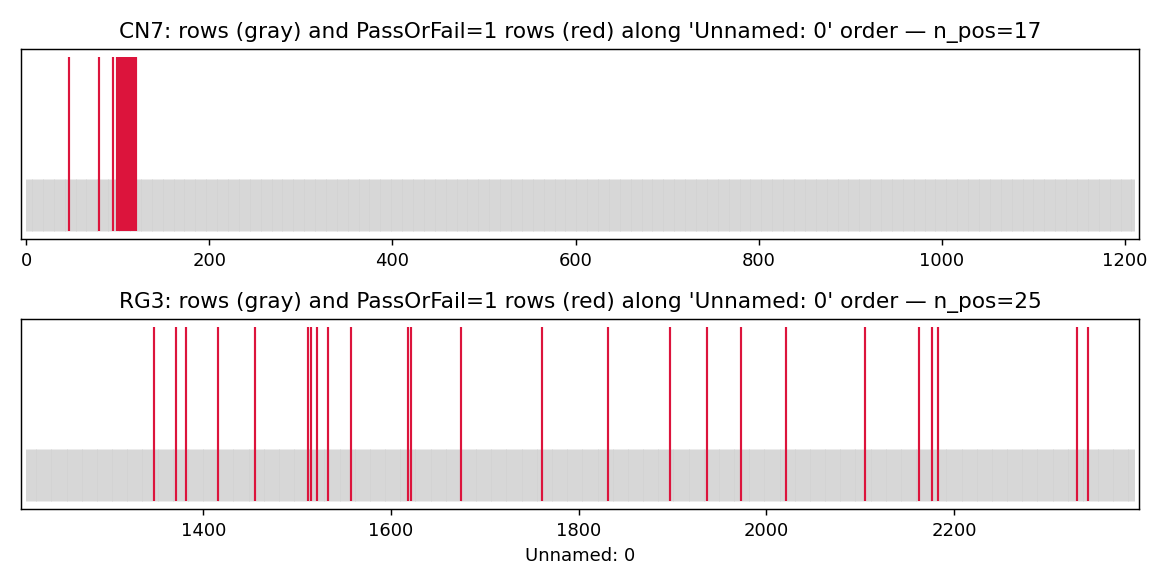

In [5]:
id_analysis = bl.analyze_id_column(dfs)
bl.plot_positives_along_index(dfs)
display(Image(filename=str(bl.EDA_DIR / "positives_along_index.png")))

**확인 결과**
- labeled: CN7 은 0~1210, RG3 는 1211~2392 로 **연속된 행 번호** (원래 하나의 표를 CN7/RG3 로 나눈 흔적). unlabeled: 114610~795309 사이의 띄엄띄엄한 번호(더 큰 원본 표에서 추출된 흔적)이고, ID 순으로 보면 CN7/RG3 가 32개 구간으로 번갈아 나타납니다 (번갈아 생산한 것으로 추정).
- 주어진 순서에서 인접 행의 공정변수 자기상관이 **0.7~0.8** 로 매우 높고, 순서를 섞으면 0 근처로 떨어집니다. → 이 인덱스는 단순 번호가 아니라 **기록(시간) 순서를 보존**하고 있다고 보는 것이 합리적입니다.
- **CN7 의 불량 17개는 모두 ID 47~120 구간(전체의 앞 10%)에 몰려 있습니다.** 즉 CN7 불량은 사실상 *한 번의 이상 구간(episode)* 입니다. RG3 의 불량 25개는 전 구간에 흩어져 있습니다.

**결론**: `Unnamed: 0` 은 feature 로 쓰지 않고(순서를 외우는 것은 일반화가 아님) **ID 로만 보존**합니다. 예측 결과를 원본과 연결하는 키이자, 시간순 holdout 의 기준으로 씁니다.
무작위 split 은 시간적으로 이웃한(거의 같은) 행을 train/validation 양쪽에 넣게 되므로, 아래 3절에서 검증 방식을 여러 개 비교합니다.

### 1-3. 중복 행 구조 — 이 데이터의 가장 중요한 특징

`중복 행 수(모든 컬럼 기준)` 은 0 이지만, **ID 를 빼고 공정변수만 보면 labeled 의 50% 가 중복**입니다. 어떤 구조인지 더 파고듭니다.

In [6]:
dup = bl.analyze_duplicates(dfs)


------------------------------------------------------------------------------
[1] 중복 행 구조 분석 (공정변수 기준)
------------------------------------------------------------------------------


      dataset  n_rows  n_unique_feature_rows   group_size_counts  share_size2_groups_adjacent                       label_pattern_(size,n_pos)_counts  n_positive  n_positive_with_identical_negative_twin  bound_recall_at_zero_FP  bound_precision_at_full_recall  bound_f1_at_full_recall
  labeled_cn7    1211                    606      {1: 1, 2: 605}                     0.942149 {'(1, 0)': 1, '(2, 0)': 591, '(2, 1)': 11, '(2, 2)': 3}        17.0                                     11.0                 0.352941                        0.607143                 0.755556
  labeled_rg3    1182                    591            {2: 591}                     0.971235                           {'(2, 0)': 566, '(2, 1)': 25}        25.0                                     25.0                 0.000000                        0.500000                 0.666667
unlabeled_cn7   35239                  28771 {1: 22303, 2: 6468}                     0.999845                                                    

**확인 결과**
- labeled 의 거의 모든 행은 **"공정변수가 완전히 같은 인접 2행" 쌍**으로 되어 있습니다 (CN7: 605쌍 + 1개, RG3: 591쌍).
- 그런데 **불량(1) 행의 대부분은 같은 공정값을 가진 정상(0) 행과 쌍**입니다. CN7 은 17개 중 11개, RG3 는 25개 **전부**가 그렇습니다.
- 가설: 1 shot(1회 사출)에서 부품 2개(예: LH/RH)가 나오고 부품별로 검사 결과가 붙은 구조. (TODO: 원본 데이터의 PART_NAME 등으로 확인)

**왜 중요한가** — 모델은 *같은 입력에는 같은 답* 을 냅니다. 공정값이 완전히 같은 두 행 중 하나가 불량, 하나가 정상이면 어떤 모델도 둘을 구분할 수 없습니다.
따라서 이 쌍에서는 (TP+FP) 아니면 (FN+TN) 만 가능하고, 다음과 같은 **성능 상한**이 데이터 자체에 내장되어 있습니다.

| | FP 0 으로 잡을 수 있는 최대 Recall | 모든 불량을 잡을 때 최대 Precision | 그때의 F1 |
|---|---|---|---|
| CN7 | 6/17 = 0.353 | 17/28 = 0.607 | 0.756 |
| RG3 | 0/25 = 0.000 | 25/50 = 0.500 | 0.667 |

또 하나: 무작위 split 은 쌍의 한쪽을 train, 다른 쪽을 validation 에 넣습니다. 그러면 validation 행의 "정답이 붙은 복사본" 이 train 에 있는 셈이라 **누수**가 생깁니다.
그래서 3절에서 **쌍(group) 단위로 나누는 split** 을 함께 평가합니다.

### 1-4. 정상/불량 비율

`PassOrFail` 은 0/1 인데, 어느 쪽이 불량인지 데이터 설명 없이는 단정할 수 없습니다.
두 파일 모두 **1 이 소수 클래스(1.4%, 2.1%)** 이고 일반적인 사출 공정 불량률과 부합하므로 `baseline.py` 상단에 `POSITIVE_CLASS = 1` 로 두고 *"현재 1을 불량 클래스로 가정하였으며 공식 데이터 설명 확인 필요"* 라는 주석을 남겼습니다.

[target] CN7: 0 -> 1194 (98.60%), 1 -> 17 (1.40%)  (불균형 비율 약 1:70)
[target] RG3: 0 -> 1157 (97.88%), 1 -> 25 (2.12%)  (불균형 비율 약 1:46)


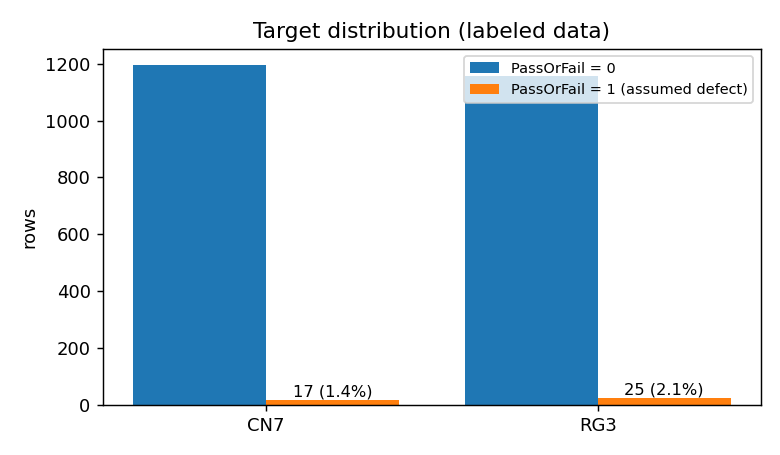

In [7]:
target_infos = [bl.analyze_target(dfs[f"labeled_{s.lower()}"], s) for s in bl.SOURCES]
pd.DataFrame(target_infos).to_csv(bl.EDA_DIR / "target_distribution.csv", index=False)
bl.plot_target_distribution(target_infos)
display(Image(filename=str(bl.EDA_DIR / "target_distribution.png")))

불균형이 매우 심합니다 (약 1:70, 1:46). 이 때문에
- Accuracy 는 "전부 정상" 이라고만 해도 98% 가 나오므로 **모델 선택 기준으로 쓰지 않습니다.**
- validation 을 20% 떼면 불량이 **3~5개** 뿐이라 holdout 지표가 매우 불안정합니다 → 보조로 5-fold CV(모든 불량이 한 번씩 평가에 포함)를 씁니다.

## 2. 데이터 분포 분석

### 2-1. 정상 vs 불량 — 어떤 변수가 다른가

[features] 공정변수 24개 중 상수 컬럼 ['Clamp_Open_Position'] 제외 → 23개 사용
           (ID 컬럼 'Unnamed: 0' 은 feature 에서 제외하고 ID 로만 보존)

[class-conditional] CN7: 정상 vs 불량 분포 차이가 큰 변수 (KS 통계량 순)
                 feature  mean_normal  mean_defect  mean_diff_defect_minus_normal  ks_stat  ks_pvalue
   Plasticizing_Position       -0.021        1.496                          1.518    0.752      0.000
      Mold_Temperature_4       -0.019        1.367                          1.386    0.715      0.000
      Mold_Temperature_3       -0.017        1.217                          1.234    0.707      0.000
       Max_Back_Pressure        0.021       -1.476                         -1.497    0.700      0.000
       Plasticizing_Time        0.006       -0.429                         -0.435    0.695      0.000
   Average_Back_Pressure        0.019       -1.341                         -1.360    0.607      0.000
        Clamp_Close_Time       -0.017        1.200                          1.217    0.544      0.000
Max


[class-conditional] RG3: 정상 vs 불량 분포 차이가 큰 변수 (KS 통계량 순)
              feature  mean_normal  mean_defect  mean_diff_defect_minus_normal  ks_stat  ks_pvalue
 Barrel_Temperature_5       -0.010        0.446                          0.455    0.185      0.330
   Mold_Temperature_4        0.002       -0.080                         -0.082    0.165      0.466
   Hopper_Temperature        0.003       -0.134                         -0.137    0.148      0.607
   Mold_Temperature_3        0.002       -0.088                         -0.090    0.143      0.648
  Max_Injection_Speed        0.001       -0.042                         -0.043    0.131      0.744
    Plasticizing_Time       -0.004        0.173                          0.177    0.121      0.821
Average_Back_Pressure       -0.001        0.060                          0.062    0.119      0.836
 Barrel_Temperature_3        0.003       -0.137                         -0.140    0.116      0.856
 Barrel_Temperature_6       -0.001        0.044    

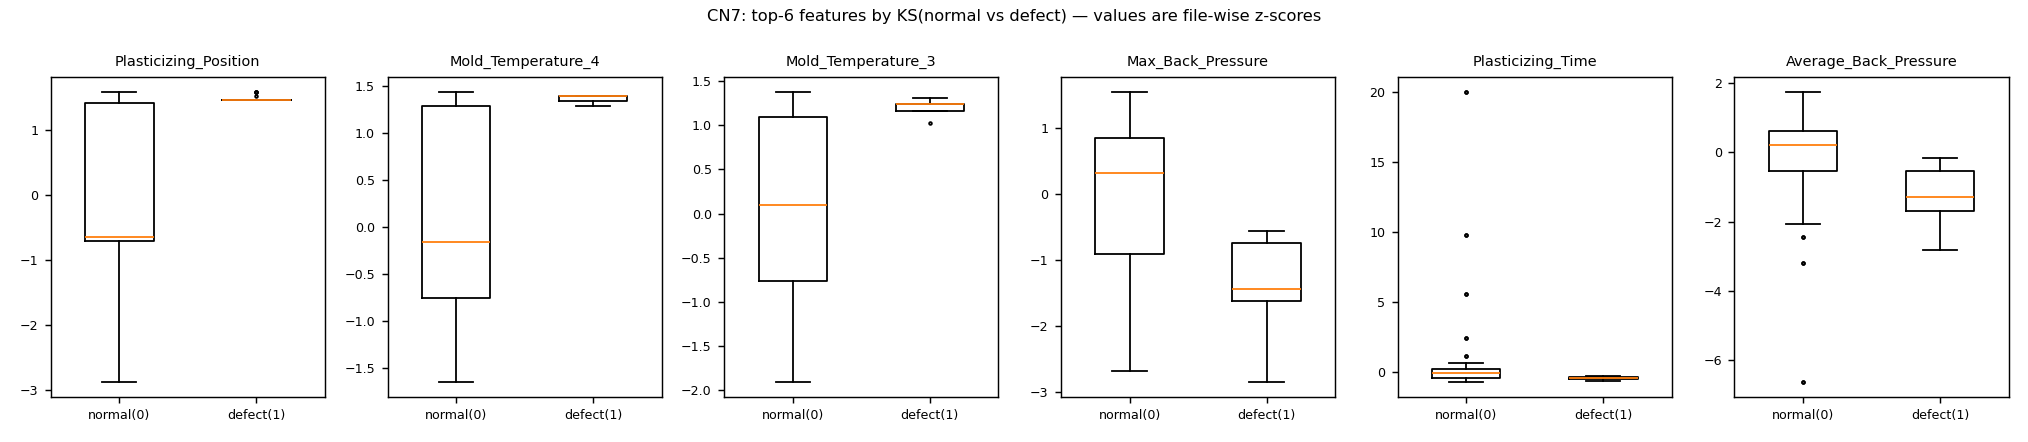

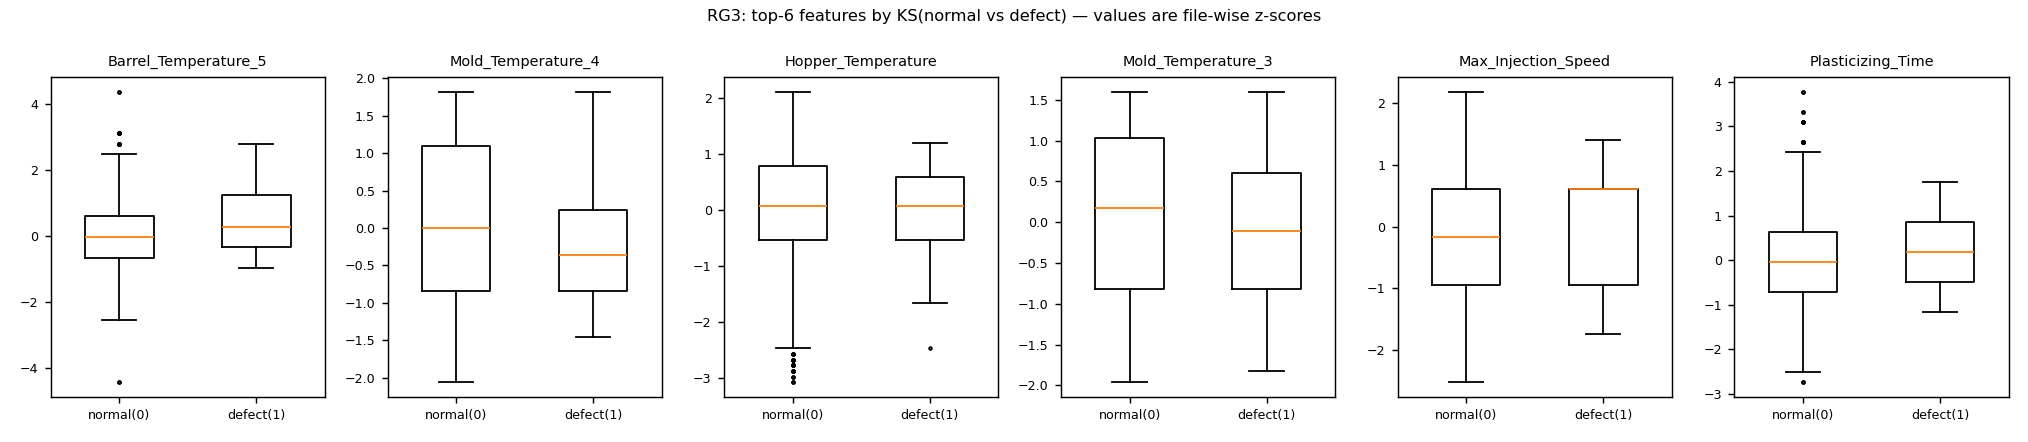

In [8]:
feats, dropped = bl.select_feature_columns(dfs)
cn7, rg3 = dfs["labeled_cn7"], dfs["labeled_rg3"]
class_cond = {s: bl.analyze_class_conditional(dfs[f"labeled_{s.lower()}"], s, feats) for s in bl.SOURCES}
for s in bl.SOURCES:
    display(Image(filename=str(bl.EDA_DIR / f"class_conditional_top_features_{s}.png")))

- **CN7**: 불량 행은 `Plasticizing_Position`, `Mold_Temperature_3/4`, `Max_Back_Pressure`, `Max_Injection_Speed` 등에서 정상과 뚜렷이 다른 값(1~3 표준편차 차이)을 가집니다. 즉 CN7 불량은 "공정 조건이 평소와 달랐던 구간" 과 겹칩니다 (1-2 의 ID 47~120 구간).
- **RG3**: 어떤 변수도 정상/불량 차이가 통계적으로 유의하지 않습니다 (KS 검정 p-value 모두 > 0.3). **현재 제공된 공정변수만으로는 RG3 불량을 구분할 근거가 거의 없다**는 뜻이고, 이는 4절의 모델 결과와 일치합니다.

### 2-2. 변수 간 상관
`Injection_Time`–`Filling_Time`(CN7), `Max_Back_Pressure`–`Average_Back_Pressure`, `Mold_Temperature_3`–`Mold_Temperature_4` 는 |r| > 0.9 로 거의 같은 정보를 담고 있습니다. Baseline 에서는 그대로 두되(트리 모델은 영향이 작고, Logistic Regression 은 계수 해석 시 주의), 다음 단계에서 정리 대상입니다.

[correlation] CN7: |r| >= 0.9 인 변수 쌍 3개
dataset          feature_a             feature_b  corr
    CN7     Injection_Time          Filling_Time 0.980
    CN7  Max_Back_Pressure Average_Back_Pressure 0.940
    CN7 Mold_Temperature_3    Mold_Temperature_4 0.978


[correlation] RG3: |r| >= 0.9 인 변수 쌍 2개
dataset          feature_a             feature_b  corr
    RG3  Max_Back_Pressure Average_Back_Pressure 0.941
    RG3 Mold_Temperature_3    Mold_Temperature_4 0.974


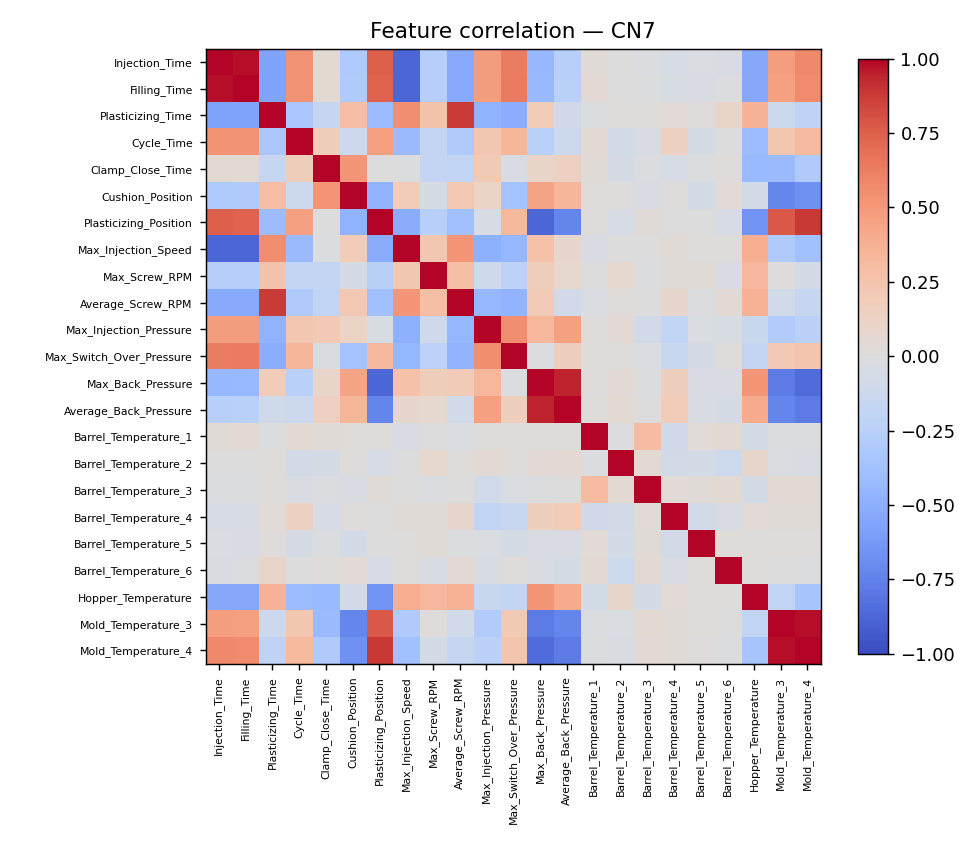

In [9]:
corr_pairs = pd.concat([bl.analyze_correlation(dfs[f"labeled_{s.lower()}"], s, feats) for s in bl.SOURCES], ignore_index=True)
display(Image(filename=str(bl.EDA_DIR / "correlation_heatmap_CN7.png")))

### 2-3. CN7 vs RG3 — 같은 분포라고 볼 수 있는가?

과제 명세대로 변수별 `CN7 mean`, `RG3 mean`, `difference`, `standardized mean difference`, `KS statistic` 을 계산합니다.
단, 1-1 에서 본 것처럼 두 파일이 따로 표준화되어 있어 **평균 차이는 0 으로 "만들어져" 있으니** 분포 *모양* 을 비교하는 KS 통계량(0=같음, 1=완전히 다름)을 봅니다.
추가로 "feature 만 보고 CN7/RG3 를 맞출 수 있는가"(도메인 분류기)를 확인합니다.


------------------------------------------------------------------------------
[2] CN7 vs RG3 분포 비교
------------------------------------------------------------------------------
                 feature  CN7_mean  RG3_mean  difference  standardized_mean_diff  CN7_n_unique  RG3_n_unique  ks_stat  ks_pvalue
              Cycle_Time       0.0       0.0        -0.0                    -0.0            13            10    0.603      0.000
       Average_Screw_RPM       0.0      -0.0         0.0                     0.0             7             4    0.576      0.000
          Injection_Time      -0.0      -0.0         0.0                     0.0            15             3    0.515      0.000
        Clamp_Close_Time      -0.0       0.0        -0.0                    -0.0             3             3    0.405      0.000
   Plasticizing_Position      -0.0       0.0        -0.0                    -0.0            13             8    0.389      0.000
            Filling_Time      -0.0      -0.0  


[도메인 분류기] feature 만으로 CN7/RG3 구분 — RandomForest AUC=1.000, LogisticRegression AUC=0.404
   AUC 가 1 에 가까우면 트리 모델은 source 컬럼이 없어도 제품을 완벽히 구분할 수 있다.
   → 실험 B 에서 source 컬럼은 '새 정보' 가 아니라 이미 feature 에 들어 있는 정보의 명시적 표기이다.


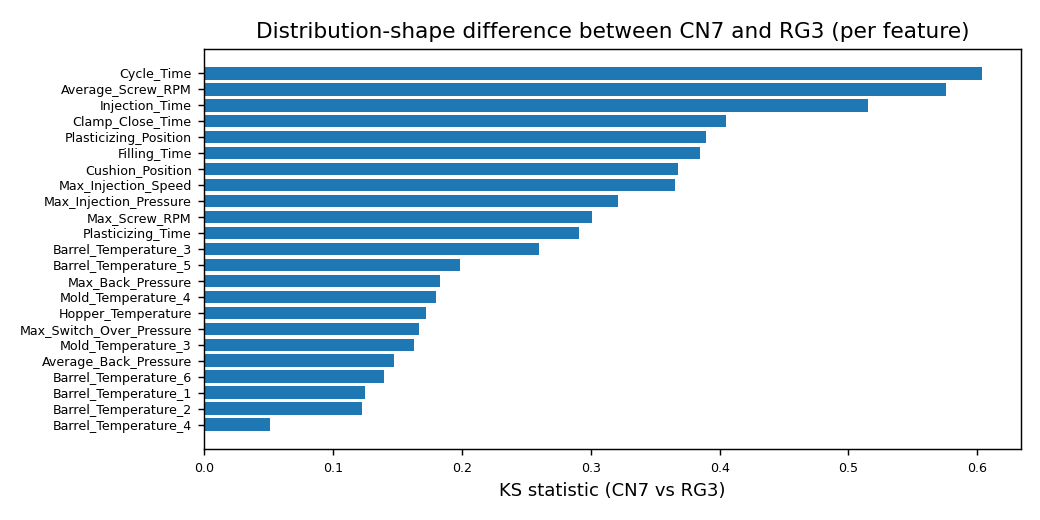

In [10]:
domain = bl.compare_domain_distribution(cn7, rg3, feats)
display(Image(filename=str(bl.EDA_DIR / "domain_comparison_ks.png")))

**확인 결과** — KS 통계량이 최대 0.60(`Cycle_Time`), 평균 0.28 이고 거의 모든 변수에서 p < 0.001 입니다. 게다가 Random Forest 는 feature 만으로 CN7/RG3 를 **AUC 1.000** 으로 완벽히 구분합니다.
(Logistic Regression 은 AUC 0.40 — 평균이 같아져 *선형으로는* 구분이 안 되지만, 값의 종류·분포 모양은 완전히 다릅니다.)

→ CN7 과 RG3 는 **같은 분포로 볼 수 없습니다.** 두 제품을 근거 없이 합치면 "두 개의 다른 문제를 억지로 하나로 푸는" 셈입니다.
그래서 실험 A(각각 학습)를 기본으로 하고, 실험 B(합치기 + `source` 컬럼)는 *이득이 분명할 때만* 채택합니다.

`source` 컬럼이 target 을 새어 나가게 하는(leakage) 컬럼인지도 점검합니다.
- 제품별 불량률은 1.4% vs 2.1% 로 차이가 0.7%p 뿐 → source 는 아주 약한 사전확률 정보일 뿐 target 을 직접 드러내지 않습니다.
- 트리 모델은 source 없이도 제품을 완벽히 구분하므로, source 컬럼은 이미 feature 에 들어 있는 정보의 명시적 표기일 뿐 **새로운 누수를 만들지 않습니다.**

### 2-4. labeled vs unlabeled (같은 제품) — 예측 대상이 학습 데이터와 같은 분포인가?

In [11]:
lab_vs_unl = bl.compare_labeled_unlabeled(dfs, feats)


------------------------------------------------------------------------------
[2] labeled vs unlabeled 분포 비교 (같은 제품)
------------------------------------------------------------------------------
feature 별 KS 통계량 요약 (labeled vs unlabeled):
         mean  median    max
source                      
CN7     0.370   0.350  0.515
RG3     0.347   0.312  0.624

[주의] labeled 와 unlabeled 도 각각 따로 표준화되어 있다. 같은 z-score 값이 같은 물리량을 뜻한다는
       보장이 없으므로 unlabeled 예측은 '상대적 순위(ranking)' 용도로만 해석해야 한다.
       TODO: 원본 단위 데이터 또는 스케일링 파라미터(평균/표준편차) 확보 필요.


같은 제품인데도 KS 통계량이 평균 0.35~0.37 로 큽니다. 두 파일이 따로 표준화된 데이터이므로 이 차이가 "실제 공정 변화" 인지 "표준화 기준(평균/표준편차)이 달라서" 인지 구분할 수 없습니다.
**unlabeled 예측은 순위 용도로만 해석**하고, 원본 단위 데이터 확보를 TODO 로 둡니다.

## 3. Train / Validation split — 세 가지 검증 방식

분류 문제이므로 기본은 **층화(stratified) 무작위 holdout** (`test_size=0.2, random_state=42`) 입니다. 그런데 1-2, 1-3 에서 본 두 가지 사실 때문에 추가 검증이 필요합니다.

| 검증 방식 | 방법 | 목적 / 한계 |
|---|---|---|
| `random_holdout` (기본) | 층화 무작위 20% | 과제 명세의 기본. 그러나 validation 행의 70~80% 는 **완전히 같은 행이 train 에 있음** (중복 쌍 누수) |
| `group_holdout` | 공정값이 같은 쌍은 반드시 같은 쪽에 (StratifiedGroupKFold 첫 fold) | 중복 쌍 누수 제거. 양성 4~8개로 여전히 불안정 |
| `ordered_holdout` | 제품별 ID(기록 순서) 뒤 20% | "과거로 미래를 예측" 하는 현실적 검증. **CN7 은 불량이 앞 10% 에만 있어 validation 에 불량 0개 → 평가 불가** |
| `cv_group5fold` (보조) | 쌍 단위 층화 5-fold, 모든 행의 OOF 확률 | 불량 17/25개 모두가 한 번씩 평가됨 → **최종 모델 선정 근거** (튜닝에는 사용 안 함) |

결과표(`model_comparison.csv`)는 명세대로 random holdout 을 기본으로 하되, 위 한계를 명시하고 다른 검증 결과를 함께 저장합니다.

In [12]:
datasets = {
    "A_CN7": bl.prepare_features(cn7, feats, "CN7", "A"),
    "A_RG3": bl.prepare_features(rg3, feats, "RG3", "A"),
    "B": bl.prepare_combined_features(cn7, rg3, feats),
}
split_infos = []
for strategy in bl.VALIDATION_STRATEGIES:
    for key, ds in datasets.items():
        tr, va = bl.split_data(ds, strategy)
        split_infos.append(bl.describe_split(ds, strategy, tr, va))
split_summary = pd.DataFrame(split_infos)
split_summary.to_csv(bl.EDA_DIR / "split_summary.csv", index=False)
split_summary

,dataset,experiment,validation,n_train,n_val,n_pos_train,n_pos_val,share_val_rows_with_identical_row_in_train
0,CN7,A,random_holdout,968,243,14,3,0.728395
1,RG3,A,random_holdout,945,237,20,5,0.839662
2,CN7+RG3,B,random_holdout,1914,479,34,8,0.807933
3,CN7,A,group_holdout,969,242,13,4,0.000000
4,RG3,A,group_holdout,946,236,20,5,0.000000
5,CN7+RG3,B,group_holdout,1913,480,34,8,0.000000
6,CN7,A,ordered_holdout,969,242,17,0,0.000000
7,RG3,A,ordered_holdout,946,236,20,5,0.000000
8,CN7+RG3,B,ordered_holdout,1915,478,37,5,0.000000


`share_val_rows_with_identical_row_in_train` 열이 핵심입니다. random holdout 에서는 validation 행의 73~84% 가 train 에 "정답이 붙은 쌍둥이" 를 갖고 있습니다. group/ordered 에서는 0% 입니다.

## 4. 전처리 · 모델 · 평가 지표

- 모든 모델은 `sklearn Pipeline` 으로 감쌉니다. `SimpleImputer`(결측 없지만 재현성용) → (Logistic Regression 만) `StandardScaler` → 모델. Pipeline 의 `fit` 은 **train 조각에만** 적용되므로 validation/unlabeled 정보가 전처리 기준에 새어 들어가지 않습니다.
- 모델: `Dummy(most_frequent / stratified)` — 기준점, `LogisticRegression(max_iter=5000)`, `RandomForest(n_estimators=300)`, `HistGradientBoosting` (sklearn 내장 GBDT — 외부 패키지 불필요).
- 불균형 처리: SMOTE 는 쓰지 않고 **기본 vs `class_weight='balanced'`** 두 조건만 비교합니다. `balanced` 는 소수 클래스(불량)의 오류에 더 큰 벌점을 주어 Recall 을 올리는 대신 FP 가 늘어나는 경향이 있습니다.
- 지표: Accuracy · Precision · Recall · F1 · ROC-AUC · PR-AUC · TN/FP/FN/TP, threshold 0.5 기준. 제조 불량 탐지이므로 **Recall 과 FN** 을 별도로 강조합니다.
- 튜닝은 하지 않습니다 (baseline).

In [13]:
models = bl.build_models()
for (name, cw), pipe in models.items():
    print(f"{name:22s} class_weight={cw:20s} steps={[s for s, _ in pipe.steps]}")

Dummy                  class_weight=most_frequent        steps=['clf']
Dummy                  class_weight=stratified           steps=['clf']
LogisticRegression     class_weight=None                 steps=['imputer', 'scaler', 'clf']
LogisticRegression     class_weight=balanced             steps=['imputer', 'scaler', 'clf']
RandomForest           class_weight=None                 steps=['imputer', 'clf']
RandomForest           class_weight=balanced_subsample   steps=['imputer', 'clf']
HistGradientBoosting   class_weight=None                 steps=['imputer', 'clf']
HistGradientBoosting   class_weight=balanced             steps=['imputer', 'clf']


In [14]:
# 실험 A (CN7, RG3 각각) + 실험 B (CN7+RG3 + source), 검증 방식 3가지
rows_all = []
for strategy in bl.VALIDATION_STRATEGIES:
    for key, ds in datasets.items():
        rows, info = bl.run_holdout_experiment(ds, models, strategy, save_artifacts=(strategy == bl.PRIMARY_VALIDATION))
        rows_all.extend(rows)

# 보조: 쌍(group) 단위 5-fold CV — 모든 행의 out-of-fold 확률
cv_rows, oof_store = [], {}
for key, ds in datasets.items():
    r, oof = bl.cross_validate_oof(ds, models)
    cv_rows.extend(r)
    oof_store[key] = oof

all_results = pd.DataFrame(rows_all + cv_rows)
spec_cols = ["experiment", "dataset", "model", "class_weight", "accuracy", "precision", "recall", "f1",
             "roc_auc", "pr_auc", "tn", "fp", "fn", "tp"]
primary = all_results[all_results["validation"] == bl.PRIMARY_VALIDATION][spec_cols + ["n_val", "n_pos_val", "validation"]]
primary.sort_values(["dataset", "f1"], ascending=[True, False]).to_csv(bl.OUTPUT_DIR / "model_comparison.csv", index=False)
all_results.to_csv(bl.OUTPUT_DIR / "model_comparison_all_validations.csv", index=False)
all_results[all_results["validation"] == bl.SELECTION_BASIS].to_csv(bl.OUTPUT_DIR / "cv_group5fold_comparison.csv", index=False)
print("저장:", bl.OUTPUT_DIR / "model_comparison.csv")


[A/CN7] validation=random_holdout: train 968 (pos 14), val 243 (pos 3), val 행 중 train 에 완전히 같은 행이 있는 비율 72.8%



[A/RG3] validation=random_holdout: train 945 (pos 20), val 237 (pos 5), val 행 중 train 에 완전히 같은 행이 있는 비율 84.0%



[B/CN7+RG3] validation=random_holdout: train 1914 (pos 34), val 479 (pos 8), val 행 중 train 에 완전히 같은 행이 있는 비율 80.8%



[A/CN7] validation=group_holdout: train 969 (pos 13), val 242 (pos 4), val 행 중 train 에 완전히 같은 행이 있는 비율 0.0%



[A/RG3] validation=group_holdout: train 946 (pos 20), val 236 (pos 5), val 행 중 train 에 완전히 같은 행이 있는 비율 0.0%



[B/CN7+RG3] validation=group_holdout: train 1913 (pos 34), val 480 (pos 8), val 행 중 train 에 완전히 같은 행이 있는 비율 0.0%



[A/CN7] validation=ordered_holdout: train 969 (pos 17), val 242 (pos 0), val 행 중 train 에 완전히 같은 행이 있는 비율 0.0%
   !! validation 에 양성(불량)이 하나도 없어 Recall/F1/AUC 를 해석할 수 없다. (표에는 남기되 참고용)



[A/RG3] validation=ordered_holdout: train 946 (pos 20), val 236 (pos 5), val 행 중 train 에 완전히 같은 행이 있는 비율 0.0%



[B/CN7+RG3] validation=ordered_holdout: train 1915 (pos 37), val 478 (pos 5), val 행 중 train 에 완전히 같은 행이 있는 비율 0.0%


저장: /home/claude/project/outputs/model_comparison.csv


## 5. 결과 비교표

### 5-1. random holdout (과제 명세의 기본 표) — F1 내림차순
`dataset` 의 `CN7+RG3[CN7]` 은 "실험 B 모델의 validation 중 CN7 부분만" 의 성능입니다. 실험 A 의 `CN7` 행과 직접 비교할 수 있습니다.

In [15]:
show_cols = ["experiment", "dataset", "model", "class_weight", "precision", "recall", "f1", "roc_auc", "pr_auc", "tn", "fp", "fn", "tp", "n_pos_val"]
def table(v):
    t = all_results[all_results["validation"] == v]
    return t.sort_values(["f1", "pr_auc"], ascending=False)[show_cols].round(3).reset_index(drop=True)
table("random_holdout")

,experiment,dataset,model,class_weight,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,n_pos_val
0,B,CN7+RG3[CN7],LogisticRegression,balanced,0.143,0.500,0.222,0.959,0.308,223,12,2,2,4
1,A,CN7,LogisticRegression,balanced,0.125,0.333,0.182,0.935,0.160,233,7,2,1,3
2,B,CN7+RG3,LogisticRegression,balanced,0.041,0.625,0.076,0.783,0.065,353,118,3,5,8
3,B,CN7+RG3[RG3],LogisticRegression,balanced,0.028,0.750,0.053,0.613,0.042,130,106,1,3,4
4,A,RG3,LogisticRegression,balanced,0.027,0.400,0.051,0.529,0.047,161,71,3,2,5
5,B,CN7+RG3[CN7],LogisticRegression,None,0.000,0.000,0.000,0.969,0.370,235,0,4,0,4
6,A,CN7,LogisticRegression,None,0.000,0.000,0.000,0.965,0.229,240,0,3,0,3
7,B,CN7+RG3[CN7],HistGradientBoosting,balanced,0.000,0.000,0.000,0.954,0.182,233,2,4,0,4
8,B,CN7+RG3[CN7],RandomForest,None,0.000,0.000,0.000,0.939,0.156,233,2,4,0,4
9,A,CN7,HistGradientBoosting,None,0.000,0.000,0.000,0.947,0.152,239,1,3,0,3


random holdout 의 validation 불량은 CN7 3개, RG3 5개뿐입니다. CN7 에서 트리 모델의 F1 이 0 인 것은 "3개 중 어느 것도 못 잡았다" 는 뜻이지만, 3개가 우연히 *정상 쌍둥이를 가진 불량* 이었다면 어떤 모델도 잡을 수 없습니다.
**이 표 하나로 모델 우열을 결정하면 안 되는 이유**입니다.

In [16]:
table("group_holdout")

,experiment,dataset,model,class_weight,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,n_pos_val
0,A,CN7,RandomForest,None,1.000,0.500,0.667,0.964,0.585,238,0,2,2,4
1,A,CN7,LogisticRegression,None,1.000,0.500,0.667,0.954,0.580,238,0,2,2,4
2,A,CN7,HistGradientBoosting,None,0.500,0.500,0.500,0.985,0.665,236,2,2,2,4
3,A,CN7,HistGradientBoosting,balanced,0.333,0.500,0.400,0.977,0.616,234,4,2,2,4
4,A,CN7,LogisticRegression,balanced,0.143,0.500,0.222,0.914,0.556,226,12,2,2,4
5,B,CN7+RG3[RG3],LogisticRegression,balanced,0.031,0.375,0.058,0.418,0.030,139,93,5,3,8
6,A,RG3,LogisticRegression,balanced,0.026,0.400,0.048,0.478,0.027,155,76,3,2,5
7,B,CN7+RG3,LogisticRegression,balanced,0.025,0.375,0.046,0.645,0.025,353,119,5,3,8
8,A,CN7,RandomForest,balanced_subsample,0.000,0.000,0.000,0.956,0.326,236,2,4,0,4
9,A,RG3,HistGradientBoosting,None,0.000,0.000,0.000,0.672,0.102,231,0,5,0,5


In [17]:
table("ordered_holdout")

,experiment,dataset,model,class_weight,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,n_pos_val
0,A,RG3,LogisticRegression,balanced,0.077,0.4,0.129,0.645,0.053,207,24,3,2,5
1,B,CN7+RG3[RG3],LogisticRegression,balanced,0.043,0.4,0.078,0.584,0.046,187,44,3,2,5
2,B,CN7+RG3,LogisticRegression,balanced,0.043,0.4,0.078,0.793,0.046,429,44,3,2,5
3,A,RG3,HistGradientBoosting,balanced,0.000,0.0,0.000,0.561,0.075,231,0,5,0,5
4,A,RG3,LogisticRegression,None,0.000,0.0,0.000,0.665,0.065,231,0,5,0,5
5,B,CN7+RG3[RG3],RandomForest,None,0.000,0.0,0.000,0.536,0.051,231,0,5,0,5
6,B,CN7+RG3[RG3],LogisticRegression,None,0.000,0.0,0.000,0.601,0.042,231,0,5,0,5
7,B,CN7+RG3,LogisticRegression,None,0.000,0.0,0.000,0.791,0.041,473,0,5,0,5
8,B,CN7+RG3,RandomForest,None,0.000,0.0,0.000,0.666,0.040,469,4,5,0,5
9,B,CN7+RG3[RG3],HistGradientBoosting,balanced,0.000,0.0,0.000,0.624,0.035,231,0,5,0,5


ordered holdout 에서 `CN7` 은 `n_pos_val = 0` (validation 에 불량 없음) → Recall/F1/AUC 가 정의되지 않습니다. RG3 만 해석 가능하며, 여기서도 Dummy 와 구분되는 모델이 없습니다.

### 5-2. 쌍(group) 단위 5-fold CV — OOF 기준 (최종 선정 근거)
불량 17개(CN7) / 25개(RG3) 가 모두 한 번씩 validation 에 들어갑니다.

In [18]:
cv_tab = all_results[all_results["validation"] == bl.SELECTION_BASIS]
cv_tab.sort_values(["dataset", "pr_auc"], ascending=[True, False])[show_cols + ["fold_f1_mean", "fold_f1_std"]].round(3).reset_index(drop=True)

,experiment,dataset,model,class_weight,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,n_pos_val,fold_f1_mean,fold_f1_std
0,A,CN7,LogisticRegression,None,0.750,0.353,0.480,0.937,0.476,1192,2,11,6,17,0.393,0.335
1,A,CN7,HistGradientBoosting,None,0.667,0.235,0.348,0.962,0.459,1192,2,13,4,17,0.233,0.291
2,A,CN7,LogisticRegression,balanced,0.145,0.529,0.228,0.932,0.441,1141,53,8,9,17,0.225,0.052
3,A,CN7,RandomForest,None,1.000,0.353,0.522,0.938,0.423,1194,0,11,6,17,0.427,0.352
4,A,CN7,HistGradientBoosting,balanced,0.429,0.353,0.387,0.945,0.385,1186,8,11,6,17,0.302,0.263
5,A,CN7,RandomForest,balanced_subsample,0.500,0.118,0.190,0.951,0.333,1192,2,15,2,17,0.133,0.267
6,A,CN7,Dummy,most_frequent,0.000,0.000,0.000,0.500,0.014,1194,0,17,0,17,0.000,0.000
7,A,CN7,Dummy,stratified,0.000,0.000,0.000,0.497,0.014,1186,8,17,0,17,0.000,0.000
8,B,CN7+RG3,LogisticRegression,None,1.000,0.143,0.250,0.743,0.203,2351,0,36,6,42,0.225,0.185
9,B,CN7+RG3,RandomForest,None,0.750,0.143,0.240,0.707,0.180,2349,2,36,6,42,0.225,0.185


**읽는 법**
- **CN7**: Logistic Regression(기본) / Random Forest(기본) / HistGradientBoosting 이 ROC-AUC 0.93~0.96, PR-AUC 0.42~0.48 로 Dummy(PR-AUC 0.014) 를 크게 앞섭니다. threshold 0.5 에서 Recall 은 정확히 **6/17 = 0.353** — 1-3 에서 계산한 "FP 0 으로 잡을 수 있는 최대 Recall" 과 같습니다. 즉 모델은 *구분 가능한 불량은 전부 잡고, 정상 쌍둥이가 있는 11개는 (데이터 구조상) 놓친* 상태입니다. `class_weight='balanced'` 는 Recall 을 0.53~0.88 로 올리지만 FP 가 53~120개로 늘어납니다 (쌍둥이 정상 행까지 같이 잡히기 때문).
- **RG3**: 모든 모델의 ROC-AUC ≈ 0.5, PR-AUC ≈ 불량률(0.021) 입니다. **현재 feature 로는 RG3 불량 신호가 없습니다.** `balanced` 로 Recall 0.32~0.48 을 만들 수는 있지만 Precision 이 0.02(=불량률) 이므로 무작위로 찍는 것과 같습니다.
- **실험 A vs B**: 제품별로 잘라 보면 B 의 성능은 A 와 같거나 조금 낮습니다. 병합의 이득이 없으므로 **실험 A(제품별 독립 모델)가 타당한 baseline 구성**입니다.

## 6. 최종 baseline 모델 선정

선정 규칙은 `baseline.select_final_models` 의 docstring 에 적혀 있습니다. 요약하면
1. group 5-fold OOF 결과만 사용 (가장 보수적)
2. 실험 A 후보 중 **PR-AUC** 최상위군(차이 0.02 이내)에서 F1 → Recall → 단순한 모델 순
3. 실험 B 는 PR-AUC 를 0.02 넘게 개선할 때만 채택 (근거 없는 병합 금지)
4. 모든 모델이 Dummy 수준이면 "신호 없음" 을 표시하고 가장 단순한 모델을 자리표시자로 둠

**단순 최고 F1 로 고르지 않는 이유**: threshold 0.5 의 F1 은 양성 수가 적어 불안정하고, 검사 우선순위(순위 매기기)에는 threshold 와 무관한 PR-AUC 가 더 적합하기 때문입니다.

In [19]:
chosen_full = bl.select_final_models(all_results, target_infos)
chosen = {s: chosen_full[s]["choice"] for s in bl.SOURCES}


------------------------------------------------------------------------------
[최종 baseline 선정] CN7
------------------------------------------------------------------------------
experiment      dataset                model       class_weight  pr_auc  roc_auc    f1  precision  recall  fn  fp
         A          CN7   LogisticRegression               None   0.476    0.937 0.480      0.750   0.353  11   2
         B CN7+RG3[CN7]   LogisticRegression               None   0.472    0.935 0.522      1.000   0.353  11   0
         B CN7+RG3[CN7] HistGradientBoosting           balanced   0.461    0.919 0.480      0.750   0.353  11   2
         A          CN7 HistGradientBoosting               None   0.459    0.962 0.348      0.667   0.235  13   2
         A          CN7   LogisticRegression           balanced   0.441    0.932 0.228      0.145   0.529   8  53
         B CN7+RG3[CN7] HistGradientBoosting               None   0.425    0.924 0.381      1.000   0.235  13   0
         A          CN

## 7. Threshold 변화에 따른 trade-off (선정 모델, OOF 확률)

0.10 ~ 0.90 사이에서 threshold 를 바꾸며 Precision / Recall / F1 / FN / FP 를 봅니다.
**주의**: 이 표로 "최적 threshold" 를 고른 뒤 같은 데이터의 성능을 최종 성능처럼 보고하지 않습니다. baseline 단계에서는 *trade-off 를 이해하는 용도* 입니다.


[CN7] ('A', 'LogisticRegression', 'None')


,threshold,precision,recall,f1,tn,fp,fn,tp,n_flagged
0,0.10,0.267,0.471,0.340,1172,22,9,8,30
1,0.15,0.444,0.471,0.457,1184,10,9,8,18
2,0.20,0.438,0.412,0.424,1185,9,10,7,16
3,0.25,0.600,0.353,0.444,1190,4,11,6,10
4,0.30,0.750,0.353,0.480,1192,2,11,6,8
5,0.35,0.750,0.353,0.480,1192,2,11,6,8
6,0.40,0.750,0.353,0.480,1192,2,11,6,8
7,0.45,0.750,0.353,0.480,1192,2,11,6,8
8,0.50,0.750,0.353,0.480,1192,2,11,6,8
9,0.55,1.000,0.353,0.522,1194,0,11,6,6


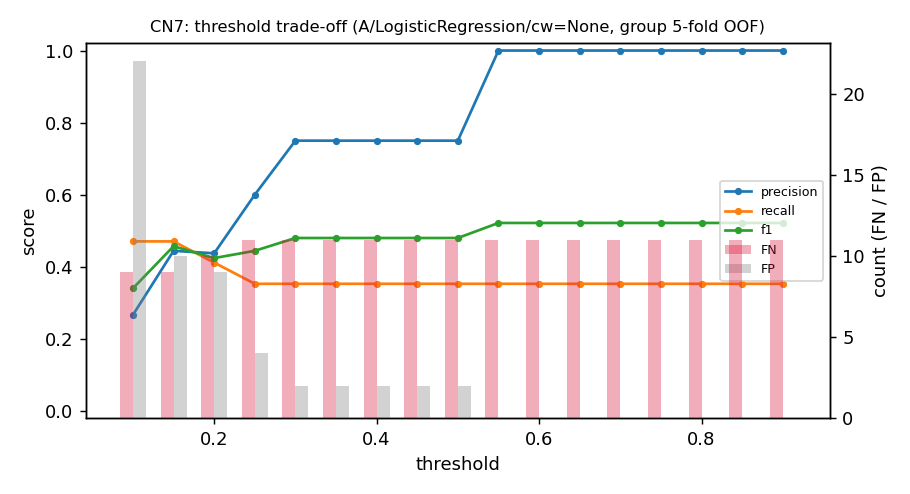


[RG3] ('A', 'LogisticRegression', 'None')


,threshold,precision,recall,f1,tn,fp,fn,tp,n_flagged
0,0.10,0.0,0.0,0.0,1139,18,25,0,18
1,0.15,0.0,0.0,0.0,1149,8,25,0,8
2,0.20,0.0,0.0,0.0,1153,4,25,0,4
3,0.25,0.0,0.0,0.0,1155,2,25,0,2
4,0.30,0.0,0.0,0.0,1157,0,25,0,0
5,0.35,0.0,0.0,0.0,1157,0,25,0,0
6,0.40,0.0,0.0,0.0,1157,0,25,0,0
7,0.45,0.0,0.0,0.0,1157,0,25,0,0
8,0.50,0.0,0.0,0.0,1157,0,25,0,0
9,0.55,0.0,0.0,0.0,1157,0,25,0,0


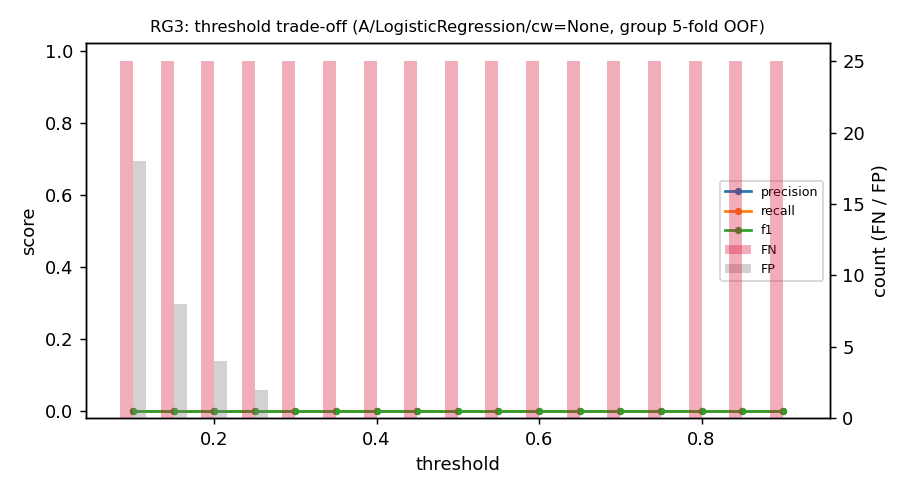

In [20]:
final = {}
for s in bl.SOURCES:
    choice = chosen[s]
    exp_key = f"A_{s}" if choice[0] == "A" else "B"
    ds = datasets[exp_key]
    oof = oof_store[exp_key][(choice[1], choice[2])]
    mask = ds.source.values == s
    thr = bl.analyze_thresholds(ds.y.values[mask], oof[mask])
    thr.to_csv(bl.THRESHOLD_DIR / f"final_{s}_threshold_performance_oof.csv", index=False)
    bl.plot_threshold_tradeoff(thr, f"{s}: threshold trade-off ({choice[0]}/{choice[1]}/cw={choice[2]}, group 5-fold OOF)",
                               bl.THRESHOLD_DIR / f"final_{s}_threshold_tradeoff_oof.png")
    final[s] = {"choice": choice, "threshold_table": thr}
    print(f"\n[{s}] {choice}")
    display(thr.round(3))
    display(Image(filename=str(bl.THRESHOLD_DIR / f"final_{s}_threshold_tradeoff_oof.png")))

- **CN7**: threshold 를 0.1 까지 내리면 Recall 0.47(8/17) 까지 올라가지만 FP 가 22개로 늘고, 0.55 이상에서는 FP 0 · Recall 0.353 으로 고정됩니다. "검사 여력이 얼마나 있는가" 에 따라 운영점을 고를 수 있는 형태이며, 실제 threshold 결정은 별도 검증(nested CV 등)으로 해야 합니다.
- **RG3**: 어느 threshold 에서도 Precision 이 불량률(0.02) 수준 → 순위 자체가 무작위에 가깝습니다.

## 8. 오류 분석용 데이터

`outputs/errors/` 에 validation 표본별로 `original_index, source, y_true, y_pred, defect_probability, error_type(TP/TN/FP/FN)` + 모든 공정 feature 를 저장했습니다.
- `*_random_holdout_validation_errors.csv`: 명세의 기본 holdout
- `*_cv_group5fold_oof_errors.csv`: **모든 labeled 행**에 대한 OOF 결과 → "FN/FP 가 어떤 공정조건에서 집중되는가" 분석에는 이 파일이 훨씬 유용합니다 (holdout 은 불량 3~5개뿐).

예시로 선정 모델의 CN7 OOF 파일에서 FN 행을 봅니다. `dup_group` 이 같은 행이 정상 쌍둥이입니다.

In [21]:
c = chosen["CN7"]
err_path = bl.ERROR_DIR / f"{bl.slug(c[0], 'CN7' if c[0]=='A' else 'CN7+RG3', c[1], c[2], bl.SELECTION_BASIS)}_oof_errors.csv"
err = pd.read_csv(err_path)
print(err_path.name, "| error_type 분포:", err["error_type"].value_counts().to_dict())
fn_rows = err[err["error_type"] == "FN"]
# FN 행과 같은 dup_group(정상 쌍둥이)을 함께 보여 준다
err[err["dup_group"].isin(fn_rows["dup_group"])].sort_values(["dup_group", "y_true"])[
    ["original_index", "dup_group", "y_true", "y_pred", "defect_probability", "error_type",
     "Plasticizing_Position", "Mold_Temperature_4", "Max_Back_Pressure", "Max_Injection_Speed"]].round(3).head(24)

A_CN7_LogisticRegression_None_cv_group5fold_oof_errors.csv | error_type 분포: {'TN': 1192, 'FN': 11, 'TP': 6, 'FP': 2}


,original_index,dup_group,y_true,y_pred,defect_probability,error_type,Plasticizing_Position,Mold_Temperature_4,Max_Back_Pressure,Max_Injection_Speed
48,48,24,0,0,0.231,TN,1.472,1.288,-0.565,-1.152
47,47,24,1,0,0.231,FN,1.472,1.288,-0.565,-1.152
79,79,40,0,0,0.014,TN,1.472,1.387,-0.741,-1.347
80,80,40,1,0,0.014,FN,1.472,1.387,-0.741,-1.347
96,96,48,0,0,0.012,TN,1.472,1.387,-1.093,-1.347
95,95,48,1,0,0.012,FN,1.472,1.387,-1.093,-1.347
100,100,50,0,0,0.019,TN,1.472,1.387,-0.565,-0.958
99,99,50,1,0,0.019,FN,1.472,1.387,-0.565,-0.958
102,102,51,0,0,0.002,TN,1.472,1.387,-0.741,-0.958
101,101,51,1,0,0.002,FN,1.472,1.387,-0.741,-0.958


FN 11개는 모두 **같은 공정값의 정상 행(TN)과 짝**을 이루고, 확률도 당연히 같습니다. 이것이 "행 단위 라벨" 문제 정의의 한계이며, 다음 단계에서 *shot 단위(쌍 단위)로 라벨을 집계*하는 문제 정의를 검토해야 하는 이유입니다.

## 9. Feature importance (인과관계 아님)

Random Forest 의 `feature_importances_` 와 Logistic Regression 의 계수(표준화된 입력 기준)를 상위 15개만 그렸습니다.
**importance 가 높다 ≠ 그 변수가 불량의 원인이다.** CN7 불량이 특정 구간에 몰려 있으므로, 그 구간의 공정 설정(예: `Plasticizing_Position`, `Mold_Temperature`)이 "그 시기를 알아보는 표식" 으로 쓰였을 가능성이 큽니다. SHAP 등 후속 분석을 위해 최종 모델은 `outputs/models/final_model_<source>.joblib` 으로 저장합니다.

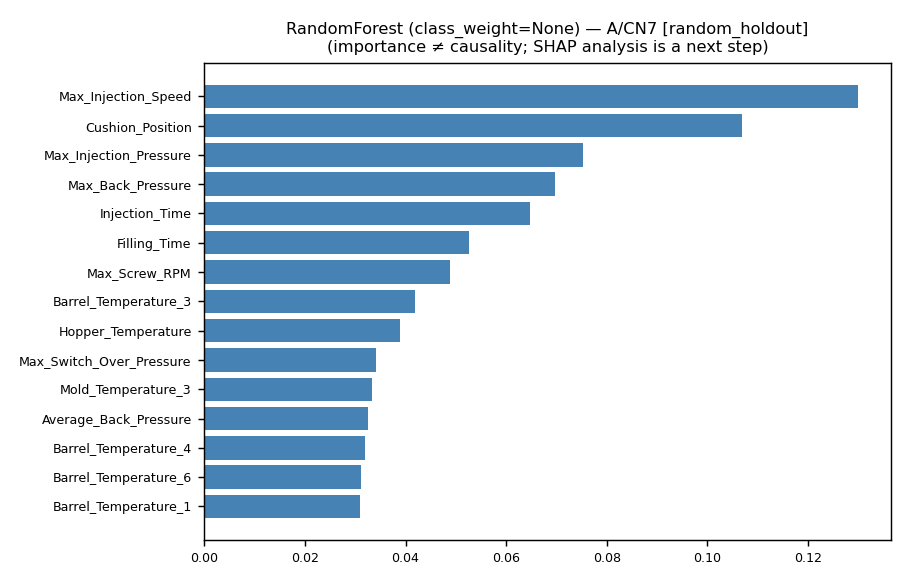

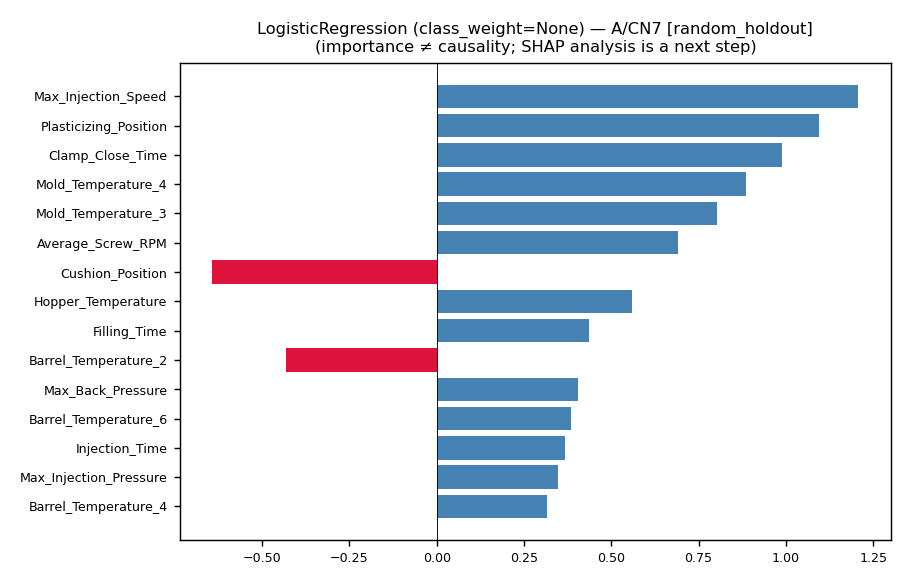

In [22]:
for p in ["A_CN7_RandomForest_None_random_holdout_feature_importance.png",
          "A_CN7_LogisticRegression_None_random_holdout_feature_importance.png"]:
    display(Image(filename=str(bl.MODEL_DIR / p)))

## 10. 최종 모델 재학습 및 unlabeled 예측

선정된 모델을 **labeled 전체**로 다시 학습한 뒤 unlabeled CN7/RG3 를 예측합니다.
결과 파일(`outputs/predictions/prediction_cn7.csv`, `prediction_rg3.csv`)에는
`original_index, source, predicted_label(threshold 0.5), defect_probability, inspection_rank` 가 들어 있습니다.
`inspection_rank` 는 불량 확률 내림차순 1부터의 순위일 뿐, **최종 검사 우선순위 알고리즘이 아닙니다** (baseline ranking).

In [23]:
pred = {}
for s in bl.SOURCES:
    choice = chosen[s]
    exp_key = f"A_{s}" if choice[0] == "A" else "B"
    model, ds_train = bl.train_final_model(choice, {"A": datasets[exp_key], "B": datasets["B"]})
    bl.save_final_model(model, ds_train, s, choice, chosen_full[s]["metrics"], no_signal=chosen_full[s]["no_signal"])
    pred[s] = bl.predict_unlabeled(model, ds_train, dfs[f"unlabeled_{s.lower()}"], s, feats, choice)
    pred[s].to_csv(bl.PRED_DIR / f"prediction_{s.lower()}.csv", index=False)
    labeled_ratio = next(t["ratio_class1"] for t in target_infos if t["dataset"] == s)
    bl.sanity_check_unlabeled_predictions(pred[s], labeled_ratio, dfs[f"labeled_{s.lower()}"], dfs[f"unlabeled_{s.lower()}"], feats)
    imp = bl.extract_importance(model, ds_train.feature_names)
    if imp is not None:
        imp.to_csv(bl.MODEL_DIR / f"final_model_{s}_feature_importance.csv", index=False)
        bl.plot_feature_importance(imp, f"Final baseline for {s}: {choice[1]} (cw={choice[2]})",
                                   bl.MODEL_DIR / f"final_model_{s}_feature_importance.png")
pred["CN7"].head(10)

[unlabeled] CN7: 35239행, 예측 불량률(0.5 기준) 4.78% (labeled 불량률 1.40%), 평균 확률 0.157, 학습 범위 밖 값을 하나라도 가진 행 61.5%
   !! 예측 불량률이 labeled 불량률의 2배를 넘는다 → labeled/unlabeled 가 따로 표준화된 영향(스케일 불일치)
      또는 실제 분포 변화 가능성. 원본 단위 확인 전까지는 확률의 절대값보다 순위(inspection_rank)만 참고.


[unlabeled] RG3: 35941행, 예측 불량률(0.5 기준) 0.01% (labeled 불량률 2.12%), 평균 확률 0.021, 학습 범위 밖 값을 하나라도 가진 행 51.2%


,original_index,source,predicted_label,defect_probability,inspection_rank
0,531124,CN7,1,0.858181,1
1,531125,CN7,1,0.858181,2
2,531047,CN7,1,0.856888,3
3,531048,CN7,1,0.856888,4
4,660292,CN7,1,0.853334,5
5,660293,CN7,1,0.848600,6
6,660166,CN7,1,0.847219,7
7,660214,CN7,1,0.844371,8
8,660290,CN7,1,0.841503,9
9,660291,CN7,1,0.840260,10


**sanity check 결과** — CN7 은 unlabeled 의 예측 불량률(0.5 기준)이 4.8% 로 labeled 불량률(1.4%)의 3배가 넘고, unlabeled 행의 61% 가 학습 범위 밖의 값을 하나 이상 가집니다. 1-1 에서 본 "labeled/unlabeled 가 따로 표준화됨" 의 영향일 가능성이 높으므로 **확률의 절대값이 아니라 순위만** 참고해야 합니다. RG3 는 신호 자체가 없어 예측 파일은 형식상 생성한 것입니다.

## 11. 실험 A vs B 결론 및 최종 요약

`baseline.summarize` 가 명세의 15번 항목(데이터 구조 → 다음 단계)을 한 번에 출력합니다.

In [24]:
results = {"dfs": dfs, "target_infos": target_infos, "features": feats, "dropped_features": dropped,
           "domain_comparison": domain, "all_results": all_results, "chosen": chosen, "chosen_full": chosen_full,
           "final": final}
bl.summarize(results)


[15] 최종 요약
1. 데이터 구조
   - labeled_cn7: (1211, 26)
   - labeled_rg3: (1182, 26)
   - unlabeled_cn7: (35239, 25)
   - unlabeled_rg3: (35941, 25)
   - 사용 feature 23개 (상수 컬럼 ['Clamp_Open_Position'] 제외), ID='Unnamed: 0', target='PassOrFail'
   - 모든 파일이 각각 표준화(z-score)되어 있으며, labeled 는 '동일 공정값 인접 2행' 쌍 구조(약 50% 중복)
2. 정상/불량 비율 (1 = 불량 가정)
   - CN7: 정상 1194 / 불량 17 (1.40%)
   - RG3: 정상 1157 / 불량 25 (2.12%)
3. CN7/RG3 분포 차이
   - 평균 차이는 표준화 때문에 0 (비교 불가). KS 통계량 평균 0.279, 최대 0.603 (Cycle_Time) → 분포 모양이 뚜렷이 다름
   - 도메인 분류기 AUC: RF 1.000 / LR 0.404
4. 각 모델 성능: outputs/model_comparison.csv (random holdout), outputs/model_comparison_all_validations.csv, outputs/cv_group5fold_comparison.csv 참고
   [CN7, cv_group5fold]
experiment                model       class_weight    f1  precision  recall  pr_auc  roc_auc  fn  fp
         A   LogisticRegression               None 0.480      0.750   0.353   0.476    0.937  11   2
         B   LogisticRegression               None 0.522      1.000   0.353   0.472 

### 한 줄 결론
- **타당한 baseline 구성 = 실험 A (CN7, RG3 각각 독립 모델).** 두 제품은 분포가 완전히 다르고(도메인 분류기 AUC 1.0), 합쳐도(실험 B) 제품별 성능이 나아지지 않는다.
- **CN7**: Logistic Regression(기본) — ROC-AUC 0.94, PR-AUC 0.48, threshold 0.5 에서 Recall 0.353(=데이터 구조상 FP 0 상한) · FN 11 · FP 2. Random Forest / HistGradientBoosting 도 동급.
- **RG3**: 어떤 모델도 Dummy 를 넘지 못함 → 공정변수 외 정보(원본 단위, 시간, 금형/설비 이벤트 등)가 필요.
- 가장 큰 발견은 모델이 아니라 **데이터 구조**다: (1) 파일별 독립 표준화, (2) 공정값이 같은 2행 쌍에 상반된 라벨, (3) CN7 불량의 단일 구간 집중. 이 세 가지가 다음 단계의 문제 정의를 결정한다.

### 다음 단계 (제안)
1. shot(쌍) 단위 라벨 집계(any-defect)로 문제 재정의 → 성능 상한 제거, 검사 단위와도 일치
2. 원본 단위 데이터 / 스케일링 파라미터 확보 → unlabeled 예측의 절대 확률 신뢰 가능하게
3. `PassOrFail` 0/1 의미 공식 확인
4. OOF 오류 파일로 FN/FP 집중 공정조건 분석 + SHAP
5. threshold 는 nested CV 로 결정, 검사 여력 대비 Recall 우선 운영점 설계
6. CN7 은 추가 기간 데이터 확보 전까지 시간순 검증 불가함을 보고서에 명시